<a href="https://colab.research.google.com/github/Hajara03/Group3_project/blob/main/notebooks/Computer_Vision_Parallel_Project_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Import libraries

In [ ]:
import os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet50, ResNet50_Weights
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

Using: cuda


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

DATASET_PATH = "/content/drive/MyDrive/asl-alphabet-train"

# Check that the path is correct
import os
print("Folder exists:", os.path.exists(DATASET_PATH))


Folder exists: True


In [ ]:
#Reading images
extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
records = []

for class_name in sorted(os.listdir(DATASET_PATH)):
    class_path = os.path.join(DATASET_PATH, class_name)
    if os.path.isdir(class_path):
        for file_name in os.listdir(class_path):
            if file_name.lower().endswith(extensions):
                records.append((os.path.join(class_path, file_name), class_name))

df = pd.DataFrame(records, columns=["image_path", "class_name"])
if df.empty:
    raise ValueError("No images found. Check DATASET_PATH and the class-folder structure.")

classes = sorted(df.class_name.unique())
class_to_idx = {name: i for i, name in enumerate(classes)}
df["label"] = df.class_name.map(class_to_idx)
print("Images:", len(df))
print("Classes:", classes)
display(df.head())

Images: 870
Classes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']


,image_path,class_name,label
0,/content/drive/MyDrive/asl-alphabet-train/A/A0...,A,0
1,/content/drive/MyDrive/asl-alphabet-train/A/A0...,A,0
2,/content/drive/MyDrive/asl-alphabet-train/A/A0...,A,0
3,/content/drive/MyDrive/asl-alphabet-train/A/A0...,A,0
4,/content/drive/MyDrive/asl-alphabet-train/A/A0...,A,0


##*View images*




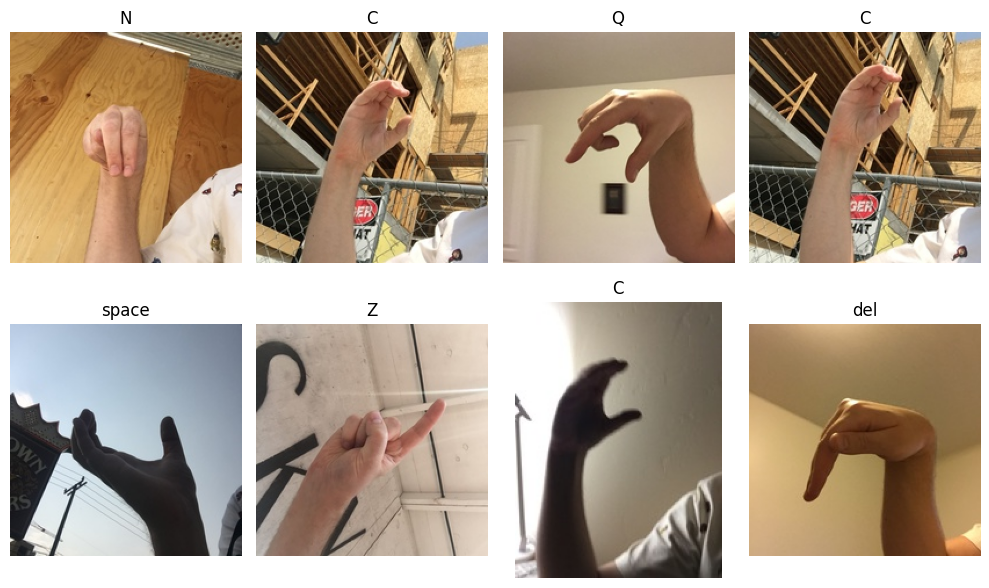

In [ ]:
plt.figure(figsize=(10, 6))
for i, row in enumerate(df.sample(min(8, len(df)), random_state=SEED).itertuples(), 1):
    plt.subplot(2, 4, i)
    plt.imshow(Image.open(row.image_path).convert("RGB"))
    plt.title(row.class_name)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 6. Split into train, validation and test sets

In [ ]:
train_val, test_df = train_test_split(df, test_size=0.10, random_state=SEED, stratify=df.label)
train_df, val_df = train_test_split(train_val, test_size=0.1111, random_state=SEED, stratify=train_val.label)
print("Train:", len(train_df), " Validation:", len(val_df), " Test:", len(test_df))

Train: 696  Validation: 87  Test: 87


## Prepare images and DataLoaders

In [ ]:
IMAGE_SIZE = 224
BATCH_SIZE = 8
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomRotation(8),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

class ASLDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, index):
        row = self.frame.iloc[index]
        image = Image.open(row.image_path).convert("RGB")
        return self.transform(image), int(row.label)

train_ds = ASLDataset(train_df, train_transform)
val_ds = ASLDataset(val_df, eval_transform)
test_ds = ASLDataset(test_df, eval_transform)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, drop_last=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

##  Load pretrained ResNet50 and replace its classifier

In [ ]:
weights = ResNet50_Weights.DEFAULT
model = resnet50(weights=weights)

# Freeze all pretrained layers
for param in model.parameters():
    param.requires_grad = False

# Create a new output layer
model.fc = nn.Linear(model.fc.in_features, len(classes))
model = model.to(device)
print(model.fc)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 200MB/s]


Linear(in_features=2048, out_features=29, bias=True)


## Training and validation function

In [ ]:
def run_epoch(loader, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, correct, total = 0, 0, 0
    criterion = nn.CrossEntropyLoss()

    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, correct / total

def train_model(epochs, optimizer, stage):
    for epoch in range(epochs):
        train_loss, train_acc = run_epoch(train_loader, optimizer)
        val_loss, val_acc = run_epoch(val_loader)
        print(f"{stage} | Epoch {epoch+1}/{epochs} | Train Acc: {train_acc:.3f} | Val Acc: {val_acc:.3f} | Train Loss: {train_loss:.3f} | Val Loss: {val_loss:.3f}")

##  Feature extraction

In [ ]:
# Only the new classifier is trained in this stage.
optimizer = torch.optim.Adam(model.fc.parameters(), lr=0.001)
train_model(epochs=20, optimizer=optimizer, stage="Feature extraction")

Feature extraction | Epoch 1/20 | Train Acc: 0.261 | Val Acc: 0.483 | Train Loss: 2.952 | Val Loss: 2.407
Feature extraction | Epoch 2/20 | Train Acc: 0.552 | Val Acc: 0.540 | Train Loss: 2.212 | Val Loss: 1.976
Feature extraction | Epoch 3/20 | Train Acc: 0.678 | Val Acc: 0.655 | Train Loss: 1.739 | Val Loss: 1.699
Feature extraction | Epoch 4/20 | Train Acc: 0.780 | Val Acc: 0.724 | Train Loss: 1.468 | Val Loss: 1.440
Feature extraction | Epoch 5/20 | Train Acc: 0.818 | Val Acc: 0.805 | Train Loss: 1.211 | Val Loss: 1.258
Feature extraction | Epoch 6/20 | Train Acc: 0.872 | Val Acc: 0.747 | Train Loss: 1.035 | Val Loss: 1.198
Feature extraction | Epoch 7/20 | Train Acc: 0.907 | Val Acc: 0.805 | Train Loss: 0.915 | Val Loss: 1.066
Feature extraction | Epoch 8/20 | Train Acc: 0.912 | Val Acc: 0.793 | Train Loss: 0.804 | Val Loss: 0.948
Feature extraction | Epoch 9/20 | Train Acc: 0.924 | Val Acc: 0.828 | Train Loss: 0.740 | Val Loss: 0.864
Feature extraction | Epoch 10/20 | Train Acc: 

## Fine-tuning

In [ ]:
# Unfreeze the final ResNet block and keep the classifier trainable.
for param in model.layer4.parameters():
    param.requires_grad = True
for param in model.fc.parameters():
    param.requires_grad = True

optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.00001)
train_model(epochs=20, optimizer=optimizer, stage="Fine-tuning")

Fine-tuning | Epoch 1/20 | Train Acc: 0.999 | Val Acc: 0.931 | Train Loss: 0.018 | Val Loss: 0.224
Fine-tuning | Epoch 2/20 | Train Acc: 1.000 | Val Acc: 0.920 | Train Loss: 0.019 | Val Loss: 0.242
Fine-tuning | Epoch 3/20 | Train Acc: 1.000 | Val Acc: 0.943 | Train Loss: 0.014 | Val Loss: 0.222
Fine-tuning | Epoch 4/20 | Train Acc: 0.999 | Val Acc: 0.920 | Train Loss: 0.013 | Val Loss: 0.224
Fine-tuning | Epoch 5/20 | Train Acc: 1.000 | Val Acc: 0.943 | Train Loss: 0.012 | Val Loss: 0.225
Fine-tuning | Epoch 6/20 | Train Acc: 0.999 | Val Acc: 0.931 | Train Loss: 0.010 | Val Loss: 0.215
Fine-tuning | Epoch 7/20 | Train Acc: 0.999 | Val Acc: 0.931 | Train Loss: 0.011 | Val Loss: 0.224
Fine-tuning | Epoch 8/20 | Train Acc: 0.999 | Val Acc: 0.931 | Train Loss: 0.012 | Val Loss: 0.208
Fine-tuning | Epoch 9/20 | Train Acc: 1.000 | Val Acc: 0.931 | Train Loss: 0.014 | Val Loss: 0.192
Fine-tuning | Epoch 10/20 | Train Acc: 0.996 | Val Acc: 0.943 | Train Loss: 0.018 | Val Loss: 0.211
Fine-tuni

##Evaluate on the test set

In [ ]:
model.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(device))
        y_pred.extend(outputs.argmax(1).cpu().numpy())
        y_true.extend(labels.numpy())

print("Test accuracy:", round(accuracy_score(y_true, y_pred) * 100, 2), "%")
print(classification_report(y_true, y_pred, target_names=classes, zero_division=0))

Test accuracy: 88.51 %
              precision    recall  f1-score   support

           A       1.00      1.00      1.00         3
           B       1.00      1.00      1.00         3
           C       1.00      1.00      1.00         3
           D       1.00      1.00      1.00         3
           E       1.00      0.67      0.80         3
           F       1.00      1.00      1.00         3
           G       1.00      1.00      1.00         3
           H       1.00      1.00      1.00         3
           I       1.00      1.00      1.00         3
           J       1.00      1.00      1.00         3
           K       0.75      1.00      0.86         3
           L       1.00      1.00      1.00         3
           M       0.50      0.33      0.40         3
           N       0.40      0.67      0.50         3
           O       1.00      1.00      1.00         3
           P       0.75      1.00      0.86         3
           Q       1.00      0.67      0.80         3
    

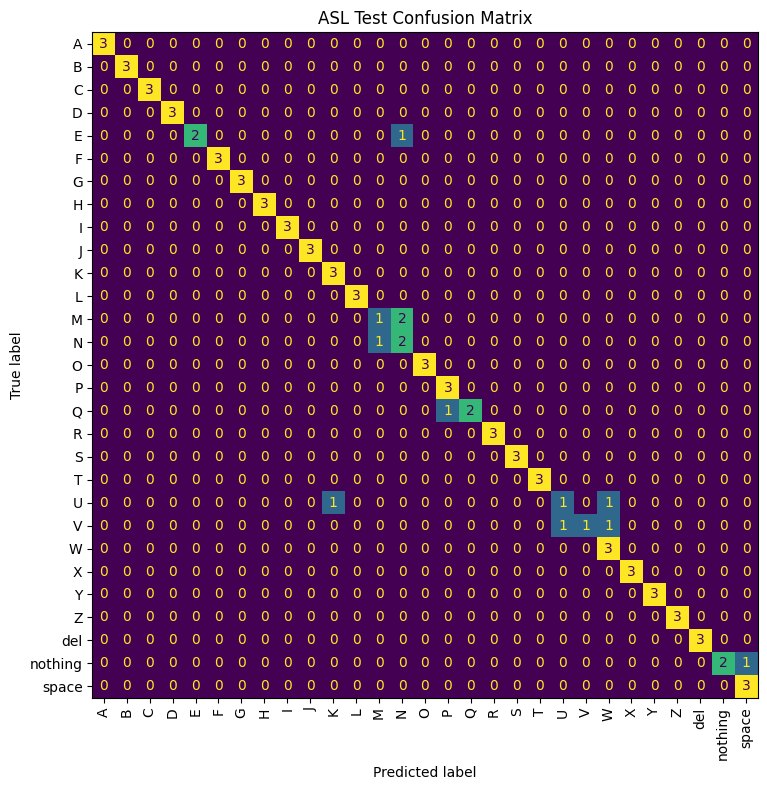

In [ ]:
#Confusion matrix
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, xticks_rotation=90, colorbar=False)
plt.title("ASL Test Confusion Matrix")
plt.tight_layout()
plt.show()

## 13. Save the trained model

In [ ]:
#Saving the model

torch.save({
    "model_state_dict": model.state_dict(),
    "classes": classes
}, "/content/drive/MyDrive/asl_resnet50_model.pth")
print("Model saved to Google Drive.")

Model saved to Google Drive.


Predicted sign: C


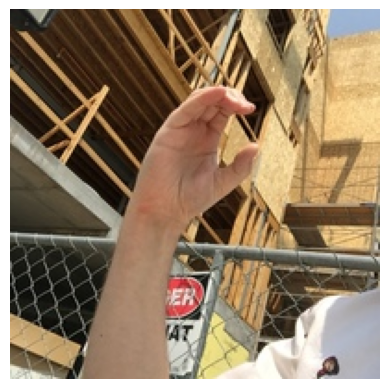

In [ ]:
IMAGE_PATH = test_df.iloc[0].image_path
image = Image.open(IMAGE_PATH).convert("RGB")
input_tensor = eval_transform(image).unsqueeze(0).to(device)
model.eval()
with torch.no_grad():
    prediction = model(input_tensor).argmax(1).item()
print("Predicted sign:", classes[prediction])
plt.imshow(image)
plt.axis("off")
plt.show()